In [3]:
import pandas as pd
import numpy as np

In [5]:
df = pd.read_csv('diabetes.csv', encoding='utf-8') 
df2 = pd.read_csv('isim_listesi1.csv', encoding='utf-8') 

In [7]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [9]:
df2

,ID,Ad,Soyad
0,0,Buse,Kaya
1,1,Gamze,Yılmaz
2,2,Sema,Şahin
3,3,Duygu,Demir
4,4,Zeynep,Çelik
...,...,...,...
763,763,Selin,Aksakal
764,764,Sude,Keskin
765,765,Zeynep,Turan
766,766,Şeyma,Özcan


In [11]:
nan_exists_all = df.isna().any()

print(nan_exists_all)

Pregnancies                 False
Glucose                     False
BloodPressure               False
SkinThickness               False
Insulin                     False
BMI                         False
DiabetesPedigreeFunction    False
Age                         False
Outcome                     False
dtype: bool


In [13]:
doluluk_orani = df.notna().mean() * 100
doluluk_orani

Pregnancies                 100.0
Glucose                     100.0
BloodPressure               100.0
SkinThickness               100.0
Insulin                     100.0
BMI                         100.0
DiabetesPedigreeFunction    100.0
Age                         100.0
Outcome                     100.0
dtype: float64

In [15]:
df = pd.read_csv('diabetes.csv')

hedef_sutunlar = ['Glucose', 'BloodPressure', 'Insulin']
nan_yuzdesi = 0.03  # %3


df_hedef = df[hedef_sutunlar]
toplam_hedef_hucre = df_hedef.size
nan_sayisi = int(toplam_hedef_hucre * nan_yuzdesi)

np.random.seed(42) 

tum_indeksler = df_hedef.stack().index

nan_pozisyonlari = np.random.choice(len(tum_indeksler), nan_sayisi, replace=False)

for satir, sutun in [tum_indeksler[i] for i in nan_pozisyonlari]:
    df.loc[satir, sutun] = np.nan
output_filename = 'diabetes_secili_random_nan.csv'
df.to_csv(output_filename, index=False)


In [17]:
nan_exists_all = df.isna().any()

print(nan_exists_all)

Pregnancies                 False
Glucose                      True
BloodPressure                True
SkinThickness               False
Insulin                      True
BMI                         False
DiabetesPedigreeFunction    False
Age                         False
Outcome                     False
dtype: bool


In [19]:
print(f"Sadece {hedef_sutunlar} sütunlarında toplam {nan_sayisi} adet eksik veri eklendi.")
print(f"Yeni DataFrame, {output_filename} adıyla kaydedildi.")
print(df.isna().sum())

Sadece ['Glucose', 'BloodPressure', 'Insulin'] sütunlarında toplam 69 adet eksik veri eklendi.
Yeni DataFrame, diabetes_secili_random_nan.csv adıyla kaydedildi.
Pregnancies                  0
Glucose                     25
BloodPressure               19
SkinThickness                0
Insulin                     25
BMI                          0
DiabetesPedigreeFunction     0
Age                          0
Outcome                      0
dtype: int64


In [21]:
doluluk_orani = df.notna().mean() * 100
doluluk_orani

Pregnancies                 100.000000
Glucose                      96.744792
BloodPressure                97.526042
SkinThickness               100.000000
Insulin                      96.744792
BMI                         100.000000
DiabetesPedigreeFunction    100.000000
Age                         100.000000
Outcome                     100.000000
dtype: float64

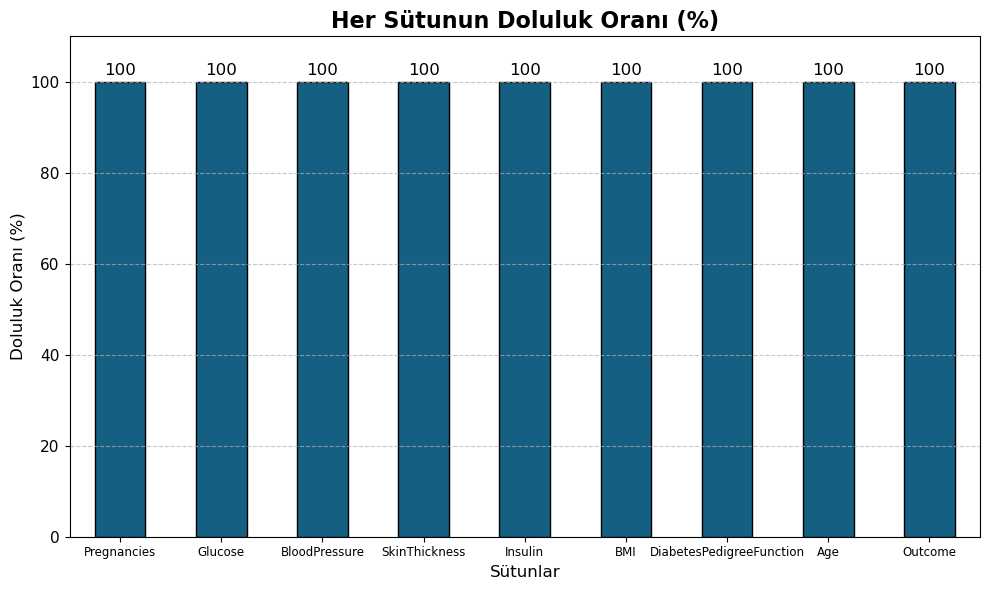

In [23]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

ax = doluluk_orani.plot(kind='bar', color='#156082', edgecolor='black')

plt.title('Her Sütunun Doluluk Oranı (%)', fontsize=16, fontweight='bold')
plt.ylabel('Doluluk Oranı (%)', fontsize=12)
plt.xlabel('Sütunlar', fontsize=12)


plt.xticks(rotation=0, fontsize=8.5)
plt.yticks(fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)

for i in ax.containers:
    ax.bar_label(i, label_type='edge', padding=3, fontsize=12)
     
plt.ylim(0, doluluk_orani.max() * 1.1)
plt.tight_layout()
plt.show()

In [24]:
 doluluk_sayisi = df.notna().sum()
 doluluk_sayisi

Pregnancies                 768
Glucose                     768
BloodPressure               768
SkinThickness               768
Insulin                     768
BMI                         768
DiabetesPedigreeFunction    768
Age                         768
Outcome                     768
dtype: int64

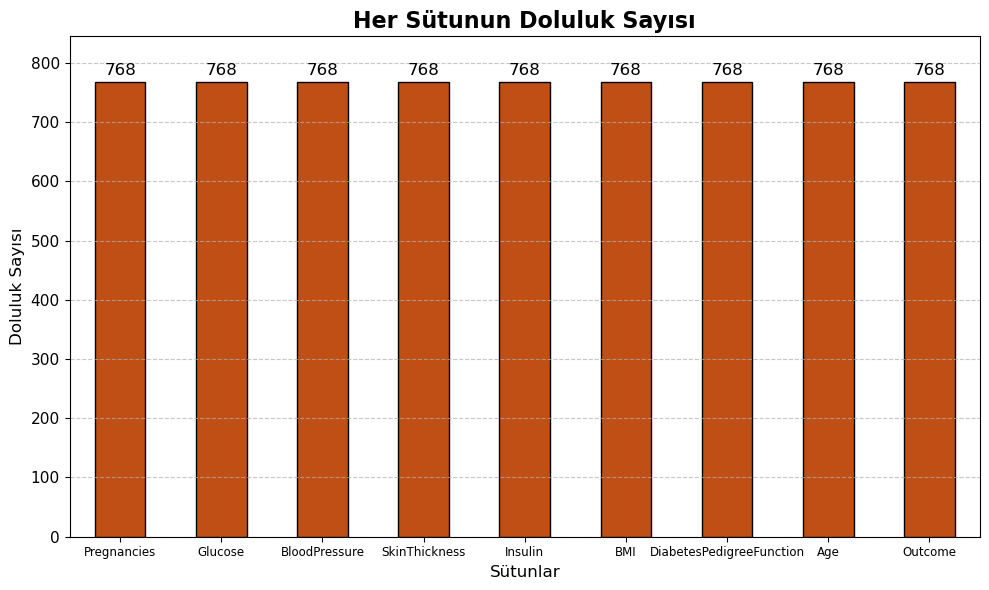

In [25]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))

ax = doluluk_sayisi.plot(kind='bar', color='#C04F15', edgecolor='black')

plt.title('Her Sütunun Doluluk Sayısı', fontsize=16, fontweight='bold')
plt.ylabel('Doluluk Sayısı', fontsize=12)
plt.xlabel('Sütunlar', fontsize=12)

plt.xticks(rotation=0, fontsize=8.5)
plt.yticks(fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)

for i in ax.containers:
    ax.bar_label(i, label_type='edge', padding=3, fontsize=12)
    
plt.ylim(0, doluluk_sayisi.max() * 1.1)
plt.tight_layout()
plt.show()

In [41]:
df['Glucose'].mean()

120.76985195154778

In [43]:
df['Glucose'].fillna(df['Glucose'].mean(), inplace=True)
df['BloodPressure'].fillna(df['BloodPressure'].mean(), inplace=True)
df['Insulin'].fillna(df['Insulin'].mean(), inplace=True)
df

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12796\3674715373.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Glucose'].fillna(df['Glucose'].mean(), inplace=True)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_12796\3674715373.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

F

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48,180.0,32.9,0.171,63,0
764,2,122.0,70.0,27,0.0,36.8,0.340,27,0
765,5,121.0,72.0,23,112.0,26.2,0.245,30,0
766,1,126.0,60.0,0,0.0,30.1,0.349,47,1


In [33]:
print(df.isna().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [45]:
most_frequent_value = df['Glucose'].mode()[0] 
df['Glucose'].fillna(most_frequent_value, inplace=True) 
 
df

C:\Users\ASUS\AppData\Local\Temp\ipykernel_12796\3630182970.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Glucose'].fillna(most_frequent_value, inplace=True)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35,0.0,33.6,0.627,50,1
1,1,85.0,66.0,29,0.0,26.6,0.351,31,0
2,8,183.0,64.0,0,0.0,23.3,0.672,32,1
3,1,89.0,66.0,23,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35,168.0,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48,180.0,32.9,0.171,63,0
764,2,122.0,70.0,27,0.0,36.8,0.340,27,0
765,5,121.0,72.0,23,112.0,26.2,0.245,30,0
766,1,126.0,60.0,0,0.0,30.1,0.349,47,1


In [47]:
print(df.isna().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [49]:
most_frequent_value

120.76985195154778

In [51]:
mode_values = df['Glucose'].mode()

if len(mode_values) > 1:
    second_most_frequent_value = mode_values[1]
else:
    second_most_frequent_value = None 
second_most_frequent_value

In [53]:
nan_exists  = df['Glucose'].isna().any()
print(nan_exists )

False


In [45]:
nan_exists  = df['Insulin'].isna().any()
print(nan_exists )

False


In [47]:
nan_exists  = df['BloodPressure'].isna().any()
print(nan_exists )

False


In [49]:
df2 = pd.read_csv('isim_listesi1.csv', encoding='utf-8') 

In [51]:
df2

,ID,Ad,Soyad
0,0,Buse,Kaya
1,1,Gamze,Yılmaz
2,2,Sema,Şahin
3,3,Duygu,Demir
4,4,Zeynep,Çelik
...,...,...,...
763,763,Selin,Aksakal
764,764,Sude,Keskin
765,765,Zeynep,Turan
766,766,Şeyma,Özcan


In [53]:
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [55]:
df2.head()

,ID,Ad,Soyad
0,0,Buse,Kaya
1,1,Gamze,Yılmaz
2,2,Sema,Şahin
3,3,Duygu,Demir
4,4,Zeynep,Çelik


In [57]:
merged_df = pd.merge(df, df2, left_index=True, right_on='ID')
merged_df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik
...,...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,763,Selin,Aksakal
764,2,122,70,27,0,36.8,0.340,27,0,764,Sude,Keskin
765,5,121,72,23,112,26.2,0.245,30,0,765,Zeynep,Turan
766,1,126,60,0,0,30.1,0.349,47,1,766,Şeyma,Özcan


In [59]:
merged_df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik
...,...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,763,Selin,Aksakal
764,2,122,70,27,0,36.8,0.340,27,0,764,Sude,Keskin
765,5,121,72,23,112,26.2,0.245,30,0,765,Zeynep,Turan
766,1,126,60,0,0,30.1,0.349,47,1,766,Şeyma,Özcan


In [61]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['Glucose Normalized'] = scaler.fit_transform(merged_df[['Glucose']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya,0.743719
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin,0.919598
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir,0.447236
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442


In [62]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
merged_df['Glucose Z-Score Normalized'] = scaler.fit_transform(merged_df[['Glucose']])

merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,Glucose Z-Score Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.848324
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,-1.123396
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,1.943724
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir,0.447236,-0.998208
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.504055


In [63]:
import numpy as np
def decimal_scaling(series):
    max_abs_value = np.abs(series).max()  
    scale_factor = np.ceil(np.log10(max_abs_value)) 
    return series / 10**scale_factor  
merged_df['Glucose Decimal Normalized'] = decimal_scaling(merged_df['Glucose'])
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.848324,0.148
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,-1.123396,0.085
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,1.943724,0.183
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir,0.447236,-0.998208,0.089
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.504055,0.137


In [67]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['BloodPressure Normalized'] = scaler.fit_transform(merged_df[['BloodPressure']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized,BloodPressure Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.848324,0.148,0.590164
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,-1.123396,0.085,0.540984
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,1.943724,0.183,0.524590
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir,0.447236,-0.998208,0.089,0.540984
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.504055,0.137,0.327869


In [69]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['SkinThickness Normalized'] = scaler.fit_transform(merged_df[['SkinThickness']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized,BloodPressure Normalized,SkinThickness Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.848324,0.148,0.590164,0.353535
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,-1.123396,0.085,0.540984,0.292929
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,1.943724,0.183,0.524590,0.000000
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir,0.447236,-0.998208,0.089,0.540984,0.232323
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.504055,0.137,0.327869,0.353535


In [71]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['Insulin Normalized'] = scaler.fit_transform(merged_df[['Insulin']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.848324,0.148,0.590164,0.353535,0.000000
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,-1.123396,0.085,0.540984,0.292929,0.000000
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,1.943724,0.183,0.524590,0.000000,0.000000
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir,0.447236,-0.998208,0.089,0.540984,0.232323,0.111111
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.504055,0.137,0.327869,0.353535,0.198582


In [73]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['BMI Normalized'] = scaler.fit_transform(merged_df[['BMI']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.848324,0.148,0.590164,0.353535,0.000000,0.500745
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,-1.123396,0.085,0.540984,0.292929,0.000000,0.396423
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,1.943724,0.183,0.524590,0.000000,0.000000,0.347243
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir,0.447236,-0.998208,0.089,0.540984,0.232323,0.111111,0.418778
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.504055,0.137,0.327869,0.353535,0.198582,0.642325


In [75]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['DiabetesPedigreeFunction Normalized'] = scaler.fit_transform(merged_df[['DiabetesPedigreeFunction']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,Ad,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,Buse,Kaya,0.743719,0.848324,0.148,0.590164,0.353535,0.000000,0.500745,0.234415
1,1,85,66,29,0,26.6,0.351,31,0,1,Gamze,Yılmaz,0.427136,-1.123396,0.085,0.540984,0.292929,0.000000,0.396423,0.116567
2,8,183,64,0,0,23.3,0.672,32,1,2,Sema,Şahin,0.919598,1.943724,0.183,0.524590,0.000000,0.000000,0.347243,0.253629
3,1,89,66,23,94,28.1,0.167,21,0,3,Duygu,Demir,0.447236,-0.998208,0.089,0.540984,0.232323,0.111111,0.418778,0.038002
4,0,137,40,35,168,43.1,2.288,33,1,4,Zeynep,Çelik,0.688442,0.504055,0.137,0.327869,0.353535,0.198582,0.642325,0.943638


In [77]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['Age Normalized'] = scaler.fit_transform(merged_df[['Age']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,...,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized,Age Normalized
0,6,148,72,35,0,33.6,0.627,50,1,0,...,Kaya,0.743719,0.848324,0.148,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,1,85,66,29,0,26.6,0.351,31,0,1,...,Yılmaz,0.427136,-1.123396,0.085,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,8,183,64,0,0,23.3,0.672,32,1,2,...,Şahin,0.919598,1.943724,0.183,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,1,89,66,23,94,28.1,0.167,21,0,3,...,Demir,0.447236,-0.998208,0.089,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0,137,40,35,168,43.1,2.288,33,1,4,...,Çelik,0.688442,0.504055,0.137,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000


In [79]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
merged_df['Outcome'] = scaler.fit_transform(merged_df[['Outcome']])
 
merged_df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,...,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized,Age Normalized
0,6,148,72,35,0,33.6,0.627,50,1.0,0,...,Kaya,0.743719,0.848324,0.148,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,1,85,66,29,0,26.6,0.351,31,0.0,1,...,Yılmaz,0.427136,-1.123396,0.085,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,8,183,64,0,0,23.3,0.672,32,1.0,2,...,Şahin,0.919598,1.943724,0.183,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,1,89,66,23,94,28.1,0.167,21,0.0,3,...,Demir,0.447236,-0.998208,0.089,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0,137,40,35,168,43.1,2.288,33,1.0,4,...,Çelik,0.688442,0.504055,0.137,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000


In [81]:
merged_df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome,ID,...,Soyad,Glucose Normalized,Glucose Z-Score Normalized,Glucose Decimal Normalized,BloodPressure Normalized,SkinThickness Normalized,Insulin Normalized,BMI Normalized,DiabetesPedigreeFunction Normalized,Age Normalized
0,6,148,72,35,0,33.6,0.627,50,1.0,0,...,Kaya,0.743719,0.848324,0.148,0.590164,0.353535,0.000000,0.500745,0.234415,0.483333
1,1,85,66,29,0,26.6,0.351,31,0.0,1,...,Yılmaz,0.427136,-1.123396,0.085,0.540984,0.292929,0.000000,0.396423,0.116567,0.166667
2,8,183,64,0,0,23.3,0.672,32,1.0,2,...,Şahin,0.919598,1.943724,0.183,0.524590,0.000000,0.000000,0.347243,0.253629,0.183333
3,1,89,66,23,94,28.1,0.167,21,0.0,3,...,Demir,0.447236,-0.998208,0.089,0.540984,0.232323,0.111111,0.418778,0.038002,0.000000
4,0,137,40,35,168,43.1,2.288,33,1.0,4,...,Çelik,0.688442,0.504055,0.137,0.327869,0.353535,0.198582,0.642325,0.943638,0.200000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0.0,763,...,Aksakal,0.507538,-0.622642,0.101,0.622951,0.484848,0.212766,0.490313,0.039710,0.700000
764,2,122,70,27,0,36.8,0.340,27,0.0,764,...,Keskin,0.613065,0.034598,0.122,0.573770,0.272727,0.000000,0.548435,0.111870,0.100000
765,5,121,72,23,112,26.2,0.245,30,0.0,765,...,Turan,0.608040,0.003301,0.121,0.590164,0.232323,0.132388,0.390462,0.071307,0.150000
766,1,126,60,0,0,30.1,0.349,47,1.0,766,...,Özcan,0.633166,0.159787,0.126,0.491803,0.000000,0.000000,0.448584,0.115713,0.433333


In [83]:
reduced_df = merged_df[['BMI', 'Ad', 'Age', 'Glucose Normalized', 'Insulin']]
 
reduced_df.head()

,BMI,Ad,Age,Glucose Normalized,Insulin
0,33.6,Buse,50,0.743719,0
1,26.6,Gamze,31,0.427136,0
2,23.3,Sema,32,0.919598,0
3,28.1,Duygu,21,0.447236,94
4,43.1,Zeynep,33,0.688442,168


In [87]:
output_filename = 'diabetes_temizlenmis_ve_normalize_edilmis.csv'
merged_df.to_csv(output_filename, index=False)

print(f"Temizlenmiş ve normalleştirilmiş DataFrame, {output_filename} adıyla kaydedildi.")

Temizlenmiş ve normalleştirilmiş DataFrame, diabetes_temizlenmis_ve_normalize_edilmis.csv adıyla kaydedildi.


In [61]:
import pandas as pd
import numpy as np
np.random.seed(42)
glucose = np.random.randint(530, 10000, size=100)  
glucose[::10] = np.random.randint(50000, 100000, size=10)  
df = pd.DataFrame({'Glucose': glucose})

print("Gürültülü Veri:")
df.head(15)

Gürültülü Veri:


,Glucose
0,85222
1,1390
2,5920
3,5721
4,6264
5,6795
6,996
7,4956
8,6108
9,8852


In [63]:
df_sorted = df.sort_values(by='Glucose')
df_sorted

,Glucose
82,594
28,719
91,921
6,996
11,1299
...,...
60,74538
30,80818
90,82482
0,85222


In [65]:
bins = pd.cut(df_sorted['Glucose'], bins=5, labels=False)
 
bins

82    0
28    0
91    0
6     0
11    0
     ..
60    4
30    4
90    4
0     4
70    4
Name: Glucose, Length: 100, dtype: int64

In [67]:
df_sorted['Glucose Düzeltilmiş'] = df_sorted.groupby(bins)['Glucose'].transform('mean')

print("\nDüzeltilmiş Veri:")
df_sorted.head(100)


Düzeltilmiş Veri:


,Glucose,Glucose Düzeltilmiş
82,594,5494.655556
28,719,5494.655556
91,921,5494.655556
6,996,5494.655556
11,1299,5494.655556
...,...,...
60,74538,83118.000000
30,80818,83118.000000
90,82482,83118.000000
0,85222,83118.000000


In [69]:
 import pandas as pd
 pd.set_option("display.max_rows", None)
 pd.set_option("display.max_columns", None)

In [71]:
df_sorted

,Glucose,Glucose Düzeltilmiş
82,594,5494.655556
28,719,5494.655556
91,921,5494.655556
6,996,5494.655556
11,1299,5494.655556
48,1305,5494.655556
1,1390,5494.655556
72,1408,5494.655556
62,1525,5494.655556
65,1546,5494.655556


In [73]:
df_sorted.sort_index(inplace=True)
df_sorted

,Glucose,Glucose Düzeltilmiş
0,85222,83118.000000
1,1390,5494.655556
2,5920,5494.655556
3,5721,5494.655556
4,6264,5494.655556
5,6795,5494.655556
6,996,5494.655556
7,4956,5494.655556
8,6108,5494.655556
9,8852,5494.655556


In [75]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [76]:
np.random.seed(42)
glucose = np.random.randint(530, 10000, size=100) 
glucose[::10] = np.random.randint(50000, 100000, size=10)  

df = pd.DataFrame({'Glucose': glucose})
df.head(10)

,Glucose
0,85222
1,1390
2,5920
3,5721
4,6264
5,6795
6,996
7,4956
8,6108
9,8852


In [77]:
kmeans = KMeans(n_clusters=2, random_state=42)
df['Küme'] = kmeans.fit_predict(df[['Glucose']])
 
print("Kümelenmiş Veri:")
df

Kümelenmiş Veri:


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Glucose,Küme
0,85222,1
1,1390,0
2,5920,0
3,5721,0
4,6264,0
5,6795,0
6,996,0
7,4956,0
8,6108,0
9,8852,0


In [80]:
centroids = kmeans.cluster_centers_
threshold = np.mean(centroids)  
df['Aykırı'] = df['Glucose'] > threshold

print("\nAykırı Değerler:")
df[df['Aykırı']]


Aykırı Değerler:


,Glucose,Küme,Aykırı
0,85222,1,True
10,61837,1,True
20,64039,1,True
30,80818,1,True
40,69115,1,True
50,60965,1,True
60,74538,1,True
70,92530,1,True
80,55056,1,True
90,82482,1,True


In [83]:
df_cleaned = df[~df['Aykırı']]

print("\nTemizlenmiş Veri:")
df_cleaned.head(10)


Temizlenmiş Veri:


,Glucose,Küme,Aykırı
1,1390,0,False
2,5920,0,False
3,5721,0,False
4,6264,0,False
5,6795,0,False
6,996,0,False
7,4956,0,False
8,6108,0,False
9,8852,0,False
11,1299,0,False


In [85]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

np.random.seed(42)
glucose = np.random.randint(530, 10000, size=100)  
glucose[::10] = np.random.randint(50000, 100000, size=10) 

df = pd.DataFrame({'Glucose': glucose })
df.head(10)

,Glucose
0,85222
1,1390
2,5920
3,5721
4,6264
5,6795
6,996
7,4956
8,6108
9,8852


In [87]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Küme'] = kmeans.fit_predict(df[['Glucose']])
 
print("Kümelenmiş Veri:")
df

Kümelenmiş Veri:


C:\Users\ASUS\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,Glucose,Küme
0,85222,1
1,1390,0
2,5920,2
3,5721,2
4,6264,2
5,6795,2
6,996,0
7,4956,0
8,6108,2
9,8852,2



Küme Merkezleri (Centroids):
[[ 2679.91891892]
 [72660.2       ]
 [ 7459.66037736]]


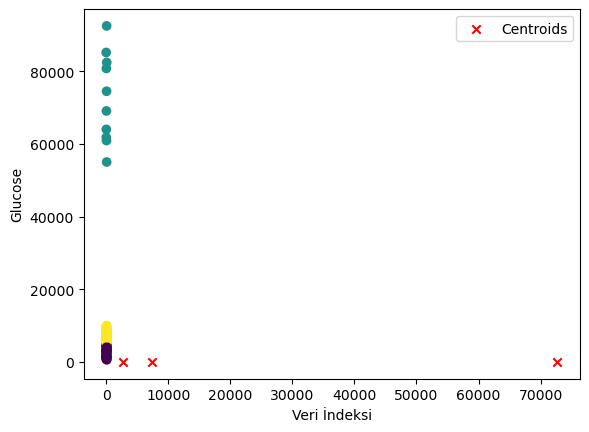

In [89]:
centroids = kmeans.cluster_centers_
print("\nKüme Merkezleri (Centroids):")
print(centroids)

plt.scatter(df.index, df['Glucose'], c=df['Küme'], cmap='viridis')
plt.scatter(centroids, [0, 0, 0], c='red', marker='x', label='Centroids')
plt.xlabel('Veri İndeksi')
plt.ylabel('Glucose')
plt.legend()
plt.show()

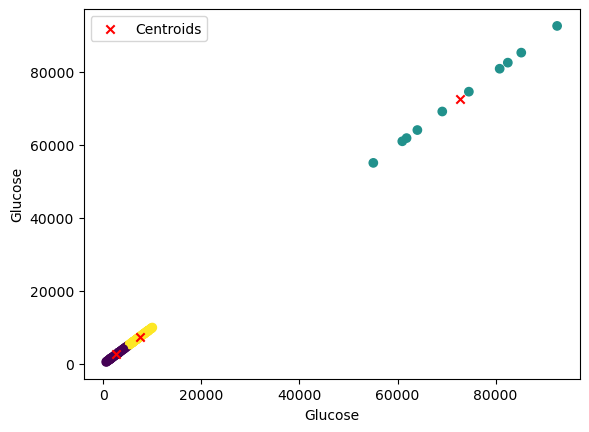

In [93]:
plt.scatter(df['Glucose'], df['Glucose'], c=df['Küme'], cmap='viridis')
plt.scatter(centroids, centroids, c='red', marker='x', label='Centroids')
plt.xlabel('Glucose')
plt.ylabel('Glucose')
plt.legend()
plt.show()

In [95]:
highest_centroid = centroids.max() 
df['Aykırı'] = df['Glucose'] > highest_centroid  
 
print("\nAykırı Değerler:")
print(df[df['Aykırı']])
 
df_cleaned = df[~df['Aykırı']]
 
print("\nTemizlenmiş Veri:")
df_cleaned


Aykırı Değerler:
    Glucose  Küme  Aykırı
0     85222     1    True
30    80818     1    True
60    74538     1    True
70    92530     1    True
90    82482     1    True

Temizlenmiş Veri:


,Glucose,Küme,Aykırı
1,1390,0,False
2,5920,2,False
3,5721,2,False
4,6264,2,False
5,6795,2,False
6,996,0,False
7,4956,0,False
8,6108,2,False
9,8852,2,False
10,61837,1,False


In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
np.random.seed(42)
glucose = np.random.randint(70, 200, size=100)
insulin = 3 * glucose + np.random.randint(-100, 100, size=100) 
df = pd.DataFrame({
'Glucose': glucose,
'Insulin': insulin
})

df.head(10)

,Glucose,Insulin
0,172,467
1,162,481
2,84,283
3,176,578
4,141,465
5,90,340
6,172,444
7,191,508
8,144,344
9,157,530


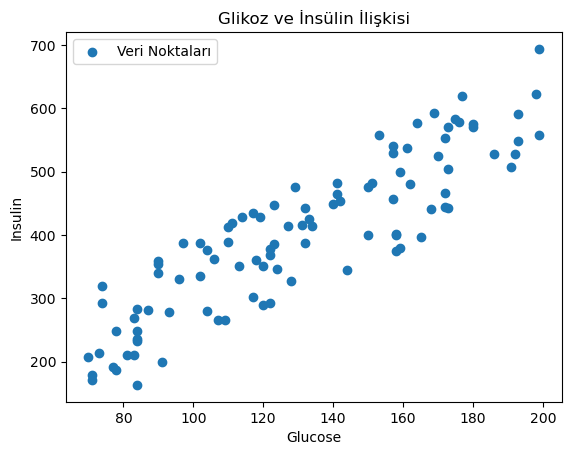

In [103]:
plt.scatter(df['Glucose'], df['Insulin'], label='Veri Noktaları')
plt.xlabel('Glucose')
plt.ylabel('Insulin')
plt.title('Glikoz ve İnsülin İlişkisi')
plt.legend()
plt.show()

Katsayı (Eğim): 2.9077
Sabit: 21.0249


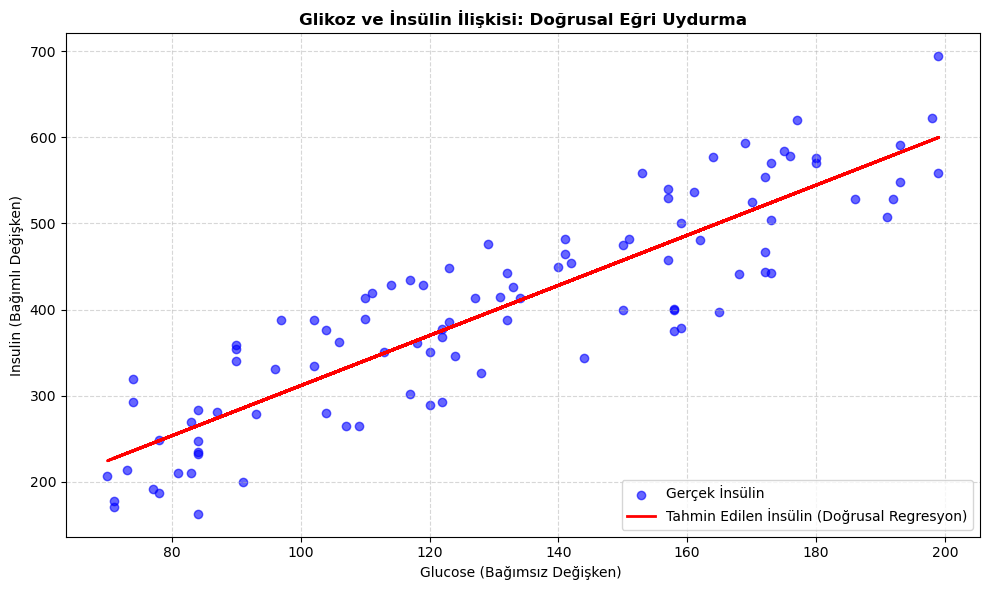

In [105]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

model = LinearRegression()

X = df[['Glucose']] 
y = df['Insulin']  

model.fit(X, y)

df['Tahmin Edilen Insulin'] = model.predict(X)

print(f"Katsayı (Eğim): {model.coef_[0]:.4f}")
print(f"Sabit: {model.intercept_:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(df['Glucose'], df['Insulin'], label='Gerçek İnsülin', color='blue', alpha=0.6)
plt.plot(df['Glucose'], df['Tahmin Edilen Insulin'], label='Tahmin Edilen İnsülin (Doğrusal Regresyon)', color='red', linewidth=2)
plt.xlabel('Glucose (Bağımsız Değişken) ')
plt.ylabel('Insulin (Bağımlı Değişken)')
plt.legend(loc='lower right')
plt.title('Glikoz ve İnsülin İlişkisi: Doğrusal Eğri Uydurma', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Aykırı Değerler (Eşik > 75):
    Glucose  Insulin  Tahmin Edilen Insulin  İnsülin Hatası
6       172      444             521.148605      -77.148605
8       144      344             439.733123      -95.733123
11      169      593             512.425518       80.574482
13      122      293             375.763816      -82.763816
20       91      200             285.625247      -85.625247
21      158      401             480.440864      -79.440864
25      120      289             369.948425      -80.948425
26      177      620             535.687084       84.312916
30       90      359             282.717551       76.282449
33      158      400             480.440864      -80.440864
34      129      476             396.117687       79.882313
37      159      379             483.348560     -104.348560
39      199      694             599.656391       94.343609
40      153      558             465.902385       92.097615
55      164      577             497.887039       79.112961
57       84

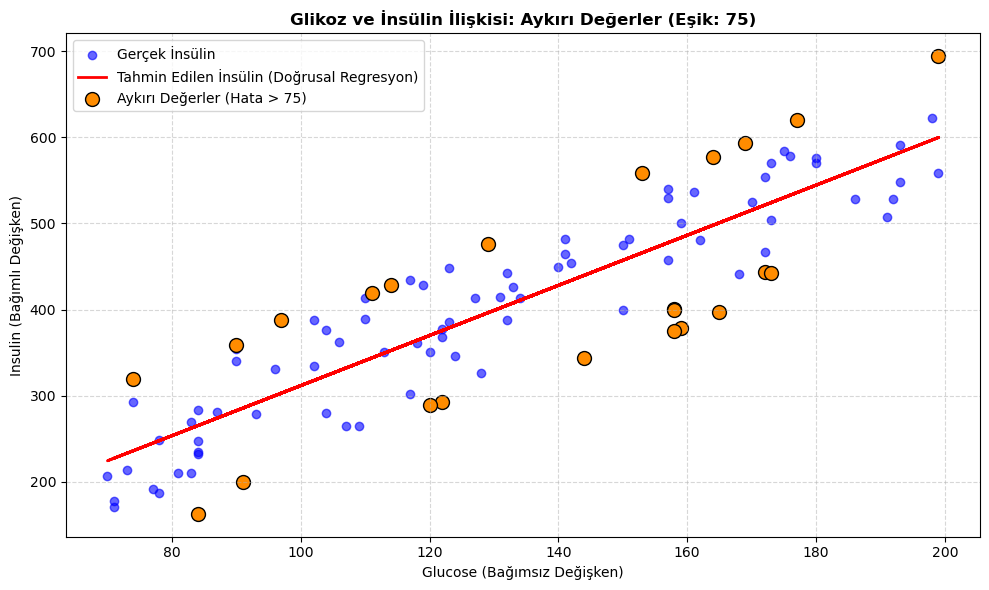

In [109]:
df['İnsülin Hatası'] = df['Insulin'] - df['Tahmin Edilen Insulin']

outlier_threshold = 75 
aykiri_degerler = df[np.abs(df['İnsülin Hatası']) > outlier_threshold]

print("Aykırı Değerler (Eşik > 75):")
print(aykiri_degerler)

plt.figure(figsize=(10, 6))
plt.scatter(df['Glucose'], df['Insulin'], label='Gerçek İnsülin', color='blue', alpha=0.6)
plt.plot(df['Glucose'], df['Tahmin Edilen Insulin'], label='Tahmin Edilen İnsülin (Doğrusal Regresyon)', color='red', linewidth=2)
plt.scatter(aykiri_degerler['Glucose'], aykiri_degerler['Insulin'], label=f'Aykırı Değerler (Hata > {outlier_threshold})', color='darkorange', s=100, edgecolors='black')
plt.xlabel('Glucose (Bağımsız Değişken)')
plt.ylabel('Insulin (Bağımlı Değişken)')
plt.legend()
plt.title(f'Glikoz ve İnsülin İlişkisi: Aykırı Değerler (Eşik: {outlier_threshold})', fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [113]:
from scipy import stats
import numpy as np

df['Z-Score'] = np.abs(stats.zscore(df['İnsülin Hatası']))

aykiri_degerler = df[df['Z-Score'] > 3]

print(aykiri_degerler)

Empty DataFrame
Columns: [Glucose, Insulin, Tahmin Edilen Insulin, İnsülin Hatası, Z-Score]
Index: []


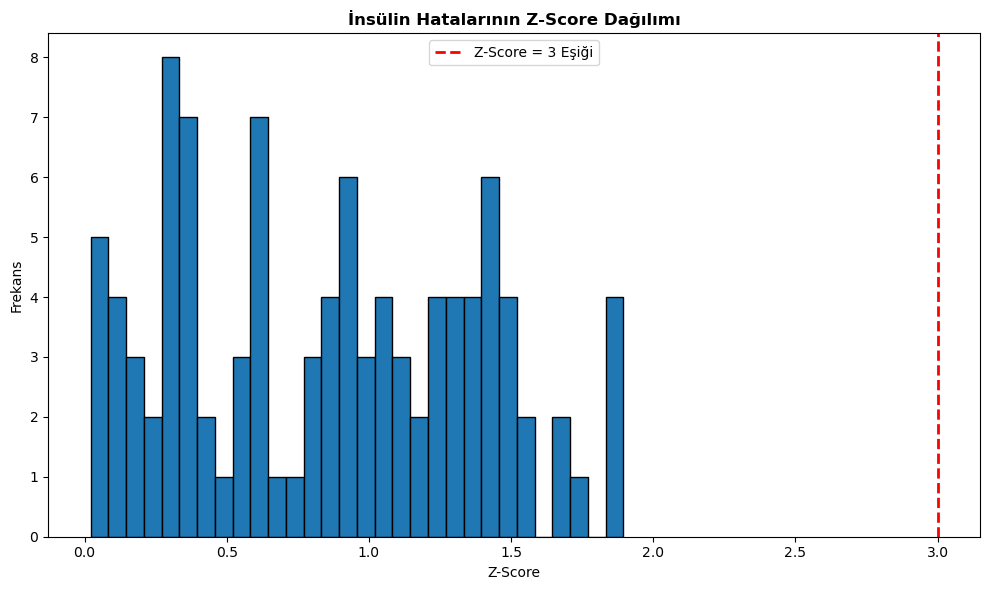

Z-Score'u 3'ten büyük olan aykırı değerler:
Empty DataFrame
Columns: [Glucose, Insulin, Tahmin Edilen Insulin, İnsülin Hatası, Z-Score]
Index: []

Z-Score'u 2.5'ten büyük olan aykırı değerler:
Empty DataFrame
Columns: [Glucose, Insulin, Tahmin Edilen Insulin, İnsülin Hatası, Z-Score]
Index: []


In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df['Z-Score'] = np.abs(stats.zscore(df['İnsülin Hatası']))

plt.figure(figsize=(10, 6))
plt.hist(df['Z-Score'], bins=30, edgecolor='k')
plt.axvline(3, color='red', linestyle='dashed', linewidth=2, label='Z-Score = 3 Eşiği')
plt.xlabel('Z-Score')
plt.ylabel('Frekans')
plt.title('İnsülin Hatalarının Z-Score Dağılımı', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

aykiri_degerler_3 = df[df['Z-Score'] > 3]

print("Z-Score'u 3'ten büyük olan aykırı değerler:")
print(aykiri_degerler_3)

if aykiri_degerler_3.empty:
    aykiri_degerler_2_5 = df[df['Z-Score'] > 2.5]
    print("\nZ-Score'u 2.5'ten büyük olan aykırı değerler:")
    print(aykiri_degerler_2_5)
    aykiri_degerler_final = aykiri_degerler_2_5
else:
    aykiri_degerler_final = aykiri_degerler_3

In [117]:
import numpy as np
import pandas as pd
from scipy import stats
sayılar = [1, 5, 8, 12, 15, 18, 20, 10, 7, 13, 15, 500, 950]
sayılar_df = pd.DataFrame({'Sayılar': sayılar})

sayılar_df['Z-Score'] = np.abs(stats.zscore(sayılar_df['Sayılar']))
aykiri_degerler = sayılar_df[sayılar_df['Z-Score'] > 3]

print("Z-Score ile tespit edilen aykırı değerler:")
print(aykiri_degerler)


Z-Score ile tespit edilen aykırı değerler:
    Sayılar   Z-Score
12      950  3.044571


In [123]:
Q1 = df['İnsülin Hatası'].quantile(0.25) 
Q3 = df['İnsülin Hatası'].quantile(0.75)

IQR = Q3 - Q1

aykiri_degerler = df[
    (df['İnsülin Hatası'] < (Q1 - 1.5 * IQR)) | 
    (df['İnsülin Hatası'] > (Q3 + 1.5 * IQR)) 
]

print("IQR Metodu ile tespit edilen aykırı değerler:")
print(aykiri_degerler)

IQR Metodu ile tespit edilen aykırı değerler:
Empty DataFrame
Columns: [Glucose, Insulin, Tahmin Edilen Insulin, İnsülin Hatası, Z-Score]
Index: []


In [125]:
import numpy as np
import pandas as pd

yeni_veri = [10, 12, 15, 18, 20, 25, 30, 32, 200, 500] 
veri_df = pd.DataFrame({'Değerler': yeni_veri}) 

Q1 = veri_df['Değerler'].quantile(0.25)
Q3 = veri_df['Değerler'].quantile(0.75)
IQR = Q3 - Q1

alt_sinir = Q1 - 1.5 * IQR
ust_sinir = Q3 + 1.5 * IQR

aykiri_degerler = veri_df[
    (veri_df['Değerler'] < alt_sinir) | 
    (veri_df['Değerler'] > ust_sinir)
]

print("Aykırı Değerler:")
print(aykiri_degerler)

Aykırı Değerler:
   Değerler
8       200
9       500


In [127]:
Q1

15.75

In [129]:
Q3

31.5

In [135]:
medyan = np.median(df['İnsülin Hatası'])
mad = np.median(np.abs(df['İnsülin Hatası'] - medyan))
aykiri_degerler = df[np.abs(df['İnsülin Hatası'] - medyan) > 3 * mad]
print(aykiri_degerler)

Empty DataFrame
Columns: [Glucose, Insulin, Tahmin Edilen Insulin, İnsülin Hatası, Z-Score]
Index: []


In [137]:
import numpy as np
import pandas as pd
sayılar = [1, 5, 8, 12, 15, 18, 20, 10, 7, 13, 15, 500, 950]
df = pd.DataFrame({'Sayılar': sayılar})
medyan = np.median(df['Sayılar'])
mad = np.median(np.abs(df['Sayılar'] - medyan))
aykiri_degerler = df[np.abs(df['Sayılar'] - medyan) > 3 * mad]
print("MAD ile tespit edilen aykırı değerler:")
print(aykiri_degerler)

MAD ile tespit edilen aykırı değerler:
    Sayılar
11      500
12      950


In [15]:
import pandas as pd
import numpy as np

np.random.seed(42)
ağırlık = np.random.randint(50, 120, size=10)  
boy = np.random.randint(150, 190, size=10)    
df = pd.DataFrame({
    'Ağırlık (kg)': ağırlık,
    'Boy (cm)': boy
})

df['Boy (m)'] = df['Boy (cm)'] / 100
df['BMI'] = df['Ağırlık (kg)'] / (df['Boy (m)']**2)


print("\n--- BMI Hesaplandı ---")
print(df.head())


bmi_bins = [0, 18.5, 25, 30, df['BMI'].max() + 1]
bmi_labels = ['Zayıf', 'Normal', 'Kilolu', 'Obez']


df['BMI Kategori'] = pd.cut(df['BMI'], 
                             bins=bmi_bins, 
                             labels=bmi_labels,
                             right=True) 

print("\n--- BMI Kategori Nitelik Sonuçları ---")
print(df.head())


--- BMI Hesaplandı ---
   Ağırlık (kg)  Boy (cm)  Boy (m)        BMI
0           101       187     1.87  28.882725
1            64       151     1.51  28.068944
2           110       170     1.70  38.062284
3            70       182     1.82  21.132713
4            73       161     1.61  28.162494

--- BMI Kategori Nitelik Sonuçları ---
   Ağırlık (kg)  Boy (cm)  Boy (m)        BMI BMI Kategori
0           101       187     1.87  28.882725       Kilolu
1            64       151     1.51  28.068944       Kilolu
2           110       170     1.70  38.062284         Obez
3            70       182     1.82  21.132713       Normal
4            73       161     1.61  28.162494       Kilolu
